# Milestone 3 : Construire le moteur de consolidation

## Section 0 : Ce que nous construisons

Au milestone 2, nous avons mesuré notre situation : nos livraisons coûtent
**143 422 €** sur le périmètre que nous optimisons, parce que nos camions partent
presque vides. Ici, nous construisons le **moteur** qui corrige cela.

Notre moteur fait trois choses, simplement :

1. pour chaque couple **fournisseur x usine**, il choisit **un profil de livraison
   stable** (le même rythme sur tout l'horizon) ;
2. il **regroupe** les besoins dans des camions bien remplis ;
3. il **chiffre l'économie** par rapport à notre baseline de **143 422 €**.

Nous travaillons sur notre périmètre (lignes `optimise`, H15). Les lignes
`non optimise : info manquante` restent livrées comme aujourd'hui (H16, un camion
plein chacune, **35 032 €** au pire cas) : identiques avant et après, elles ne
changent pas l'économie.

In [1]:
# Nos outils repris tels quels du milestone 2.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from collections import defaultdict, Counter

CHEMIN_PLANNING = "../data/processed/planning_propre.csv"
CHEMIN_GRILLE = "../data/processed/grille_prix.csv"
CAP_POIDS = 24500.0      # kg par camion (R2)
CAP_VOLUME = 110.4       # m3 par camion (R2)
TRANCHES_KG = [50, 100, 200, 300, 400, 500, 750, 1000, 1500, 2000, 2500, 3000, 3500, 4000]
JOURS = {0: "lundi", 1: "mardi", 2: "mercredi", 3: "jeudi", 4: "vendredi"}

planning = pd.read_csv(CHEMIN_PLANNING, parse_dates=["date", "semaine"])
grille = pd.read_csv(CHEMIN_GRILLE, index_col=0)
grille.columns = grille.columns.astype(str)
grille.index = grille.index.astype(str)

# Notre perimetre : les lignes optimisables (H15). ligne_grille en texte entier.
opt = planning[planning["statut"] == "optimise"].copy()
opt["ligne_grille"] = opt["ligne_grille"].apply(lambda x: str(int(float(x))))

def tranche_poids(kg):
    """Colonne de la grille : la tranche de poids juste au-dessus (au-dela de 4000 -> '>4000')."""
    for t in TRANCHES_KG:
        if kg <= t:
            return str(t)
    return ">4000"

def prix_camion(ligne_grille, poids_kg):
    """Prix d'un camion : la case (ligne = distance, colonne = poids) de la grille."""
    return float(grille.loc[str(ligne_grille), tranche_poids(poids_kg)])

print("Perimetre :", len(opt), "lignes,", opt.groupby(["supplier_id", "plant"]).ngroups, "couples")
print("Baseline du milestone 2 a battre : 143 422,43 EUR")

Perimetre : 4252 lignes, 171 couples
Baseline du milestone 2 a battre : 143 422,43 EUR


## Section 1 : Notre problème, posé clairement

**1. Ce que nous décidons.** Pour chaque couple fournisseur x usine, **un seul
profil de livraison**, stable sur tout l'horizon (toujours le même rythme).

**2. Ce que nous minimisons (fonction objectif).** Le **coût total de transport**,
c'est-a-dire la somme du prix de chaque camion, lu dans la grille (ligne = distance
du fournisseur, colonne = poids du camion) :

$$\text{Coût} = \sum_{\text{couples}} \; \sum_{\text{jours de livraison}} \; \sum_{\text{camions}} \; \text{prix}(\text{ligne\_grille},\ \text{poids\_camion})$$

**3. Nos contraintes**, une par ligne :

- **R1** : un besoin est livré le jour même ou **avant**, au plus **7 jours** avant, jamais en retard ;
- **R2** : un camion porte au plus **24 500 kg** et **110,4 m³** ;
- **R3** : un camion ne transporte **qu'un seul couple** fournisseur x usine ;
- **R4** : lissage, les livraisons d'une usine sont **réparties dans la semaine** ;
- livraisons du **lundi au vendredi** uniquement ; **aucune livraison la semaine de Noël** (H7) ;
- **pas de livraison avant** le premier jour de l'horizon ;
- **profil stable** : un couple livre toujours selon le même rythme.

**4. Pourquoi regrouper fait gagner.** Deux petits envois dans un seul camion
coûtent moins cher que deux camions séparés : le prix monte moins vite que le
poids. Vérifions-le sur la grille, à 50 km.

In [2]:
# Regrouper deux envois contre les livrer separement, a 50 km.
exemples = [(300, 300), (1000, 1000), (2000, 2000), (10000, 10000)]
lignes = []
for a, b in exemples:
    separe = prix_camion("50", a) + prix_camion("50", b)
    regroupe = prix_camion("50", a + b)   # a+b <= 24500 : tient dans un camion
    lignes.append({"envois (kg)": f"{a} + {b}", "2 camions separes": round(separe, 2),
                   "1 camion regroupe": round(regroupe, 2), "economie (EUR)": round(separe - regroupe, 2),
                   "economie (%)": round((separe - regroupe) / separe * 100, 1)})
gain_regroupement = pd.DataFrame(lignes)
display(gain_regroupement)

,envois (kg),2 camions separes,1 camion regroupe,economie (EUR),economie (%)
0,300 + 300,105.90,84.92,20.99,19.8
1,1000 + 1000,205.16,145.73,59.43,29.0
2,2000 + 2000,291.46,206.83,84.63,29.0
3,10000 + 10000,427.83,213.92,213.92,50.0


**Notre constat :** regrouper gagne toujours, et d'autant plus que les envois
sont gros : **19,8 %** pour 300 + 300 kg, **29 %** vers 1 à 2 t, jusqu'à **50 %**
pour 10 + 10 t. C'est la raison d'être de notre moteur.

In [3]:
# Et un envoi lourd ? Mieux vaut remplir un camion a fond avant d'en ouvrir un autre (H13).
sep = 2 * prix_camion("50", 13000)                        # 26 t coupees en deux camions egaux
plein = prix_camion("50", CAP_POIDS) + prix_camion("50", 26000 - CAP_POIDS)  # 1 plein + le reste
print("26 t a 50 km :")
print("  2 camions de 13 t      :", round(sep, 2), "EUR")
print("  1 camion plein + 1,5 t :", round(plein, 2), "EUR")
print("  economie du remplissage a fond :", round(sep - plein, 2), "EUR (", round((sep - plein) / sep * 100, 1), "% )")

26 t a 50 km :
  2 camions de 13 t      : 427.83 EUR
  1 camion plein + 1,5 t : 335.66 EUR
  economie du remplissage a fond : 92.17 EUR ( 21.5 % )


**Notre constat :** pour 26 t, **un camion plein plus un petit** coûte
**335,66 €** contre **427,83 €** en deux camions à moitié pleins, soit **21,5 %**
de moins. Notre règle H13 est donc : **remplir chaque camion au maximum avant d'en
ouvrir un autre**.

## Section 2 : Nos paramètres

Toutes nos règles réglables sont ici, en un seul endroit. Rien n'est écrit en dur
ailleurs : pour changer une règle, nous changeons cette cellule.

In [4]:
AVANCE_MAX = 7                      # R1 : au plus 7 jours d'avance, jamais de retard
SEMAINES_FERMEES = ["2026-12-21"]   # H7 : lundi des semaines sans livraison (Noel)
TOLERANCE_LISSAGE = 0.02            # H17 : pour lisser, on accepte +2 % de cout au plus

parametres = pd.DataFrame({
    "parametre": ["AVANCE_MAX (R1)", "SEMAINES_FERMEES (H7)", "TOLERANCE_LISSAGE (H17)",
                  "CAP_POIDS (R2)", "CAP_VOLUME (R2)"],
    "valeur": [f"{AVANCE_MAX} jours", ", ".join(SEMAINES_FERMEES),
               f"{TOLERANCE_LISSAGE:.0%}", f"{CAP_POIDS:.0f} kg", f"{CAP_VOLUME} m3"],
})
display(parametres)

,parametre,valeur
0,AVANCE_MAX (R1),7 jours
1,SEMAINES_FERMEES (H7),2026-12-21
2,TOLERANCE_LISSAGE (H17),2%
3,CAP_POIDS (R2),24500 kg
4,CAP_VOLUME (R2),110.4 m3


## Section 3 : Nos profils de livraison (élargis, H18)

Un **profil** décrit un rythme de livraison stable. Il a trois ingrédients :

- une **période** : livrer toutes les 1, 2, 3 ou 4 semaines ;
- une **phase** (pour les périodes > 1) : quelle semaine du cycle on livre ;
- des **jours** de livraison dans la semaine (parmi lundi à vendredi).

Un profil se répète à l'identique sur tout l'horizon. Nous ne nous limitons pas
aux profils du PDF (1, 2, 3, 5 fois par semaine) : nous testons aussi *une semaine
sur deux* et au-delà (**H18**). C'est la règle des 7 jours (R1) qui décide ensuite
si un profil est possible pour un couple donné.

In [5]:
def libelle_profil(p):
    """Libelle lisible d'un profil (ex. '2 / semaine : lundi, jeudi')."""
    noms = ", ".join(JOURS[j] for j in sorted(p["jours"]))
    if p["periode"] == 1:
        return f"{len(p['jours'])} / semaine : {noms}"
    return f"1 semaine sur {p['periode']} (semaine {p['phase'] + 1}) : {noms}"

def sous_ensembles(jours, tailles):
    """Toutes les combinaisons de jours des tailles demandees."""
    return [frozenset(c) for k in tailles for c in combinations(jours, k)]

def generer_profils():
    """Construit la liste des profils candidats (periodes 1 a 4, H18)."""
    profils = []
    # Periode 1 : toutes les combinaisons non vides des 5 jours (31 profils).
    for d in sous_ensembles([0, 1, 2, 3, 4], range(1, 6)):
        profils.append({"periode": 1, "phase": 0, "jours": d})
    # Periodes 2, 3, 4 : chaque phase, avec 1 ou 2 jours de livraison.
    for periode in (2, 3, 4):
        for phase in range(periode):
            for d in sous_ensembles([0, 1, 2, 3, 4], [1, 2]):
                profils.append({"periode": periode, "phase": phase, "jours": d})
    for p in profils:
        p["libelle"] = libelle_profil(p)
        p["type"] = "PDF" if (p["periode"] == 1 and len(p["jours"]) in (1, 2, 3, 5)) else "elargi"
    return profils

PROFILS = generer_profils()
nb_pdf = sum(p["type"] == "PDF" for p in PROFILS)
print("Profils candidats :", len(PROFILS), "| dont profils du PDF :", nb_pdf, "| profils elargis :", len(PROFILS) - nb_pdf)
exemples_idx = [
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset([0])),
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset([0, 3])),
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and len(p["jours"]) == 5),
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 2 and p["phase"] == 0 and p["jours"] == frozenset([1])),
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 3 and p["phase"] == 1 and len(p["jours"]) == 2),
    next(i for i, p in enumerate(PROFILS) if p["periode"] == 4 and p["phase"] == 2 and len(p["jours"]) == 1),
]
print("\n6 exemples de profils :")
for i in exemples_idx:
    print("  -", PROFILS[i]["libelle"])

Profils candidats : 166 | dont profils du PDF : 26 | profils elargis : 140

6 exemples de profils :
  - 1 / semaine : lundi
  - 2 / semaine : lundi, jeudi
  - 5 / semaine : lundi, mardi, mercredi, jeudi, vendredi
  - 1 semaine sur 2 (semaine 1) : mardi
  - 1 semaine sur 3 (semaine 2) : lundi, mardi
  - 1 semaine sur 4 (semaine 3) : lundi


Ensuite nous posons le **calendrier** des jours de livraison possibles : les jours
ouvrés (lundi à vendredi) du premier au dernier besoin, sans la semaine fermée. Pour
chaque profil, nous listons ses **dates de livraison** sur l'horizon.

In [6]:
d0 = opt["date"].min()
d1 = opt["date"].max()
lundi0 = d0 - pd.Timedelta(int(d0.weekday()), unit="D")   # lundi de la premiere semaine
fermees = set(pd.to_datetime(SEMAINES_FERMEES))

def semaine_fermee(dt):
    """Vrai si la date tombe dans une semaine fermee (H7)."""
    return (dt - pd.Timedelta(int(dt.weekday()), unit="D")) in fermees

jours_ouvres = pd.DatetimeIndex([d for d in pd.date_range(d0, d1, freq="D")
                                 if d.weekday() < 5 and not semaine_fermee(d)])

def dates_profil(p):
    """Les dates de livraison d'un profil sur l'horizon (semaine du cycle modulo la periode)."""
    out = []
    for d in jours_ouvres:
        if d.weekday() in p["jours"]:
            semaine = ((d - pd.Timedelta(int(d.weekday()), unit="D")) - lundi0).days // 7
            if semaine % p["periode"] == p["phase"]:
                out.append(d)
    return np.array(out, dtype="datetime64[D]")

DATES_PROFIL = [dates_profil(p) for p in PROFILS]
print("Jours ouvres de l'horizon :", len(jours_ouvres), "du", d0.date(), "au", d1.date())
ex = exemples_idx[1]
print("Dates du profil '" + PROFILS[ex]["libelle"] + "' :")
print("  ", [str(x) for x in DATES_PROFIL[ex]])

Jours ouvres de l'horizon : 30 du 2026-11-09 au 2026-12-18
Dates du profil '2 / semaine : lundi, jeudi' :
   ['2026-11-09', '2026-11-12', '2026-11-16', '2026-11-19', '2026-11-23', '2026-11-26', '2026-11-30', '2026-12-03', '2026-12-07', '2026-12-10', '2026-12-14', '2026-12-17']


**Notre constat :** nous obtenons **166 profils candidats** (26 du PDF, 140
élargis) et **30 jours ouvrés** sur l'horizon (6 semaines, du 09/11 au 18/12 ; la
semaine de Noël n'est pas dans l'horizon). Chaque profil sait lister ses dates de
livraison : tout est prêt pour l'évaluation.

## Section 4 : Comment nous évaluons un profil pour un couple

C'est le cœur du calcul. Pour un couple et un profil donnés, nous suivons **quatre
étapes** :

1. **Affecter chaque besoin à un jour de livraison** : le jour du profil le plus
   proche **avant ou égal** à la date du besoin. Si ce jour est à plus de 7 jours,
   ou s'il n'existe pas, le profil est **impossible** pour ce couple (R1).
2. **Regrouper** : tous les besoins affectés au même jour partent ensemble (un envoi).
3. **Charger les camions** : si l'envoi tient dans un camion, 1 camion ; sinon nous
   remplissons les camions un par un, lignes les plus lourdes d'abord, chacun au
   maximum ; une ligne peut être répartie sur deux camions du même jour (H3, H13).
4. **Chiffrer** : prix de chaque camion par la grille ; le coût du profil est la somme.

In [7]:
def charger_camions(poids, volume, meta=None):
    """Charge des lignes dans des camions : plus lourdes d'abord, chaque camion au maximum (H3, H13)."""
    poids = np.asarray(poids, float)
    volume = np.asarray(volume, float)
    ordre = np.argsort(poids)[::-1]          # les plus lourdes d'abord
    reste_p = poids[ordre].copy()
    reste_v = volume[ordre].copy()
    meta_ordonne = [meta[i] for i in ordre] if meta is not None else None
    camions = []
    cam_p = cam_v = 0.0
    parts = []
    i = 0
    while i < len(reste_p):
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1
            continue
        libre_p = CAP_POIDS - cam_p
        libre_v = CAP_VOLUME - cam_v
        densite = (reste_v[i] / reste_p[i]) if reste_p[i] > 1e-12 else 0.0
        ajout_p = reste_p[i]
        if ajout_p > libre_p:                # borne par le poids
            ajout_p = libre_p
        if densite > 0 and ajout_p * densite > libre_v:   # borne par le volume
            ajout_p = libre_v / densite
        if ajout_p <= 1e-9:                  # camion plein : on le ferme
            camions.append((cam_p, cam_v, parts))
            cam_p = cam_v = 0.0
            parts = []
            continue
        ajout_v = ajout_p * densite if reste_p[i] > 1e-12 else min(reste_v[i], libre_v)
        cam_p += ajout_p
        cam_v += ajout_v
        if meta_ordonne is not None:
            base = poids[ordre[i]]
            parts.append((meta_ordonne[i], ajout_p, ajout_v, ajout_p / base if base > 1e-12 else 1.0))
        reste_p[i] -= ajout_p
        reste_v[i] -= ajout_v
        if reste_p[i] <= 1e-9 and reste_v[i] <= 1e-9:
            i += 1
        if cam_p >= CAP_POIDS - 1e-6 or cam_v >= CAP_VOLUME - 1e-6:
            camions.append((cam_p, cam_v, parts))
            cam_p = cam_v = 0.0
            parts = []
    if cam_p > 1e-9 or cam_v > 1e-9 or parts:
        camions.append((cam_p, cam_v, parts))
    return camions

def cout_camions(camions, ligne_grille):
    """Somme des prix des camions d'une livraison."""
    return sum(prix_camion(ligne_grille, poids) for poids, volume, parts in camions)

# Nous precalculons, pour chaque couple, ses besoins tries par date.
COUPLES = {}
for (s, pl), g in opt.groupby(["supplier_id", "plant"]):
    g = g.sort_values("date")
    COUPLES[(s, pl)] = {"besoins": g["date"].values.astype("datetime64[D]"),
                        "poids": g["weight"].values.astype(float),
                        "volume": g["volume"].values.astype(float),
                        "ligne": g["ligne_grille"].iloc[0],
                        "distance": g["distance"].iloc[0], "df": g}

def evaluer_profil(couple, idx_profil, avance_max=None, detail=False):
    """Cout d'un profil pour un couple ; None si impossible (R1). Les 4 etapes ci-dessus."""
    am = AVANCE_MAX if avance_max is None else avance_max
    dates = DATES_PROFIL[idx_profil]
    if len(dates) == 0:
        return None
    besoins = couple["besoins"]
    pos = np.searchsorted(dates, besoins, side="right") - 1   # etape 1 : jour avant ou egal
    if (pos < 0).any():
        return None                                            # un besoin sans jour avant lui
    jour_livraison = dates[pos]
    avance = (besoins - jour_livraison).astype("timedelta64[D]").astype(int)
    if (avance > am).any():
        return None                                            # avance > 7 jours : impossible
    ligne = couple["ligne"]
    cout = 0.0
    nb_camions = 0
    jours_utilises = []
    contenu = []
    df = couple["df"]
    for u in np.unique(pos):                                   # etape 2 : regrouper par jour
        masque = pos == u
        meta = None
        if detail:
            idxs = np.where(masque)[0]
            meta = [{"material": df.iloc[j]["material"], "unloading_point": df.iloc[j]["unloading_point"],
                     "date_besoin": pd.Timestamp(besoins[j]), "quantite": df.iloc[j]["schedule_quantity"]}
                    for j in idxs]
        camions = charger_camions(couple["poids"][masque], couple["volume"][masque], meta=meta)  # etape 3
        cout += cout_camions(camions, ligne)                   # etape 4
        nb_camions += len(camions)
        jours_utilises.append(dates[u])
        if detail:
            contenu.append((pd.Timestamp(dates[u]), camions))
    return {"cout": cout, "camions": nb_camions, "livraisons": len(jours_utilises),
            "jours": np.array(jours_utilises, dtype="datetime64[D]"), "idx": idx_profil, "contenu": contenu}

print("Fonctions du moteur pretes.")

Fonctions du moteur pretes.


**Un exemple détaillé** sur un vrai couple, **SUP_00085 x PLT_004** (205
besoins sur l'horizon, distance 121 km). Comparons deux profils.

In [8]:
couple_ex = COUPLES[("SUP_00085", "PLT_004")]
print("Couple SUP_00085 x PLT_004 :", len(couple_ex["besoins"]), "besoins,",
      len(np.unique(couple_ex["besoins"])), "dates differentes, poids total",
      round(couple_ex["poids"].sum()), "kg, ligne de grille", couple_ex["ligne"])

def montrer(nom, jours):
    """Affiche le resultat d'un profil (periode 1) pour le couple d'exemple."""
    idx = next(i for i, p in enumerate(PROFILS) if p["periode"] == 1 and p["jours"] == frozenset(jours))
    r = evaluer_profil(couple_ex, idx)
    print("\n" + nom, "->", PROFILS[idx]["libelle"])
    print("   livraisons :", r["livraisons"], "| camions :", r["camions"], "| cout :", round(r["cout"], 2), "EUR")

montrer("Profil A (tous les jours, comme aujourd'hui)", [0, 1, 2, 3, 4])
montrer("Profil B (une fois par semaine, le lundi)", [0])

Couple SUP_00085 x PLT_004 : 205 besoins, 30 dates differentes, poids total 70868 kg, ligne de grille 125

Profil A (tous les jours, comme aujourd'hui) -> 5 / semaine : lundi, mardi, mercredi, jeudi, vendredi
   livraisons : 30 | camions : 30 | cout : 7429.18 EUR

Profil B (une fois par semaine, le lundi) -> 1 / semaine : lundi
   livraisons : 6 | camions : 6 | cout : 1988.44 EUR


**Notre constat :** livré tous les jours, ce couple fait **30 livraisons**
pour **7 429 €**. Regroupé une fois par semaine le lundi, il fait **6 livraisons**
pour **1 988 €**, soit **73 % de moins** : les besoins de la semaine tiennent dans
un seul camion mieux rempli. C'est exactement ce que notre moteur cherche, couple
par couple.

**Contrôle de cohérence.** Avant d'optimiser, nous vérifions que notre moteur
sait **refaire la situation actuelle** : un envoi par couple et par date réelle,
chargé et chiffré par nos fonctions. Le total doit retomber sur notre baseline du
milestone 2, **143 422,43 €**.

In [9]:
cout_actuel = 0.0
camions_actuel = 0
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    camions = charger_camions(g["weight"].values, g["volume"].values)
    cout_actuel += cout_camions(camions, g["ligne_grille"].iloc[0])
    camions_actuel += len(camions)
BASELINE = 143422.43
ok = abs(cout_actuel - BASELINE) < 0.01
print("Cout actuel recalcule :", round(cout_actuel, 2), "EUR |", camions_actuel, "camions")
print("Baseline attendue     :", BASELINE, "EUR")
print("Controle :", "OK" if ok else "ECHEC")
assert ok, "Le moteur ne retrouve pas la baseline du milestone 2."

Cout actuel recalcule : 143422.43 EUR | 1604 camions
Baseline attendue     : 143422.43 EUR
Controle : OK


**Notre constat :** le contrôle passe (**OK**) : notre moteur retrouve
exactement **143 422,43 €** et **1 604 camions**. Nos fonctions de chargement et de
prix sont fidèles ; nous pouvons nous en servir pour optimiser.

## Section 5 : Étape 1 de l'algorithme : le meilleur profil de chaque couple

Pour chaque couple, nous **testons tous les profils candidats** et gardons le moins
cher parmi ceux qui sont possibles. C'est une **recherche exhaustive**.

**Pourquoi c'est la bonne méthode.** Grâce à R3 (un camion ne porte qu'un seul
couple), le coût d'un couple **ne dépend pas des autres couples**. Chercher le
meilleur profil couple par couple donne donc le meilleur coût global : c'est
**exact**, pas une approximation. Le nombre de cas reste petit (171 couples x 166
profils), le calcul prend quelques secondes. Un solveur d'optimisation (programmation
linéaire, OR-Tools) n'apporterait rien sur le coût et serait plus difficile à
expliquer.

In [10]:
def evaluer_tous(indices, avance_max=None):
    """Pour chaque couple, la liste des profils possibles avec leur cout."""
    resultats = {}
    for cle, couple in COUPLES.items():
        possibles = []
        for i in indices:
            r = evaluer_profil(couple, i, avance_max=avance_max)
            if r is not None:
                possibles.append(r)
        resultats[cle] = possibles
    return resultats

idx_tous = list(range(len(PROFILS)))
idx_pdf = [i for i, p in enumerate(PROFILS) if p["type"] == "PDF"]

CANDIDATS = evaluer_tous(idx_tous)                 # profils elargis (H18)
meilleur = {cle: min(v, key=lambda r: r["cout"]) for cle, v in CANDIDATS.items()}
cout_etape1 = sum(b["cout"] for b in meilleur.values())
sans_profil = sum(len(v) == 0 for v in CANDIDATS.values())
print("ETAPE 1 (profils elargis)")
print("  cout total   :", round(cout_etape1, 2), "EUR")
print("  camions      :", sum(b["camions"] for b in meilleur.values()))
print("  livraisons   :", sum(b["livraisons"] for b in meilleur.values()))
print("  couples sans profil possible :", sans_profil)

ETAPE 1 (profils elargis)
  cout total   : 82710.91 EUR
  camions      : 657
  livraisons   : 645
  couples sans profil possible : 0


In [11]:
# Tableau : tous les resultats (couple, profil, possible oui/non), puis le meilleur par couple.
lignes_tous = []
for (s, pl), couple in COUPLES.items():
    possibles = {r["idx"]: r for r in CANDIDATS[(s, pl)]}
    for i in idx_tous:
        r = possibles.get(i)
        lignes_tous.append({"supplier_id": s, "plant": pl, "profil": PROFILS[i]["libelle"],
                            "possible": "oui" if r else "non",
                            "cout": round(r["cout"], 2) if r else None,
                            "camions": r["camions"] if r else None,
                            "livraisons": r["livraisons"] if r else None})
tous_resultats = pd.DataFrame(lignes_tous)
print("Tableau de tous les resultats :", len(tous_resultats), "lignes (couple x profil). Extrait :")
display(tous_resultats.head(8))

meilleur_tab = pd.DataFrame([{"supplier_id": s, "plant": pl, "profil": PROFILS[b["idx"]]["libelle"],
                              "cout": round(b["cout"], 2), "camions": b["camions"], "livraisons": b["livraisons"]}
                             for (s, pl), b in meilleur.items()])
print("\nLe meilleur profil par couple (extrait) :")
display(meilleur_tab.head(8))

Tableau de tous les resultats : 28386 lignes (couple x profil). Extrait :


,supplier_id,plant,profil,possible,cout,camions,livraisons
0,SUP_00001,PLT_004,1 / semaine : lundi,oui,169.84,2.0,2.0
1,SUP_00001,PLT_004,1 / semaine : mardi,oui,169.84,2.0,2.0
2,SUP_00001,PLT_004,1 / semaine : mercredi,oui,169.84,2.0,2.0
3,SUP_00001,PLT_004,1 / semaine : jeudi,oui,169.84,2.0,2.0
4,SUP_00001,PLT_004,1 / semaine : vendredi,oui,169.84,2.0,2.0
5,SUP_00001,PLT_004,"2 / semaine : lundi, mardi",oui,169.84,2.0,2.0
6,SUP_00001,PLT_004,"2 / semaine : lundi, mercredi",oui,169.84,2.0,2.0
7,SUP_00001,PLT_004,"2 / semaine : lundi, jeudi",oui,169.84,2.0,2.0



Le meilleur profil par couple (extrait) :


,supplier_id,plant,profil,cout,camions,livraisons
0,SUP_00001,PLT_004,1 / semaine : lundi,169.84,2,2
1,SUP_00003,PLT_001,1 / semaine : lundi,258.97,4,4
2,SUP_00005,PLT_001,1 / semaine : lundi,476.49,3,3
3,SUP_00008,PLT_002,1 / semaine : lundi,234.37,3,3
4,SUP_00009,PLT_004,1 / semaine : lundi,34.68,1,1
5,SUP_00010,PLT_001,1 / semaine : lundi,84.11,3,3
6,SUP_00010,PLT_002,1 / semaine : lundi,231.86,4,4
7,SUP_00010,PLT_004,"1 semaine sur 2 (semaine 1) : lundi, vendredi",593.17,6,6


**Notre constat :** chaque couple trouve un profil possible (**0 couple sans
solution**). Le meilleur profil de chacun ramène le coût du périmètre de
**143 422 €** à **82 711 €**, avec **657 camions** et **645 livraisons**. C'est
déjà **42 %** de moins, mais sans tenir compte de l'équilibre dans la semaine : nous
le corrigeons à l'étape 2.

## Section 6 : Étape 2 de l'algorithme : le lissage dans la semaine (R4)

**Le problème.** À l'étape 1, chaque couple a choisi son profil le moins cher, sans
se soucier des autres. Résultat : les livraisons d'une usine se **concentrent** sur
quelques jours. Regardons la charge par jour de la semaine, avant lissage.

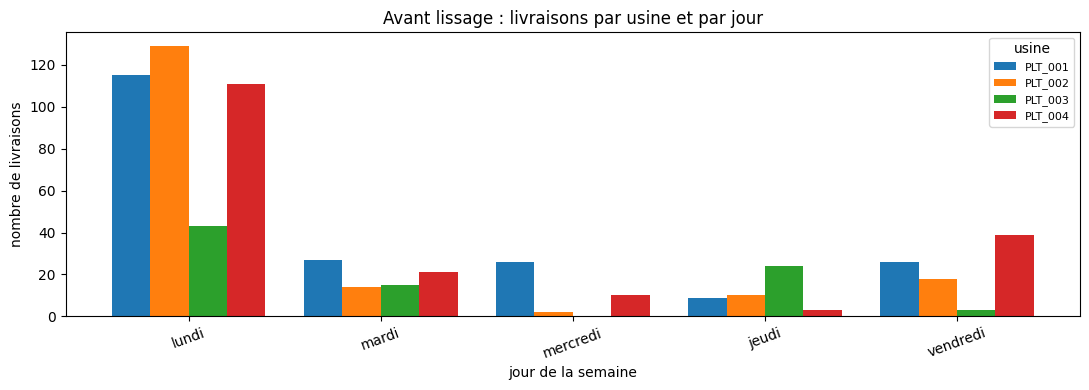

In [12]:
def charge_par_jour_semaine(choix):
    """Nombre de livraisons par usine et par jour de la semaine."""
    t = defaultdict(lambda: defaultdict(int))
    for (s, pl), b in choix.items():
        for d in b["jours"]:
            t[pl][pd.Timestamp(d).weekday()] += 1
    return t

def tracer_charge(t, titre, ax):
    """Barres groupees : livraisons par usine pour chaque jour de la semaine."""
    usines = sorted(t.keys())
    x = np.arange(5)
    larg = 0.8 / len(usines)
    for i, u in enumerate(usines):
        vals = [t[u].get(j, 0) for j in range(5)]
        ax.bar(x + (i - (len(usines) - 1) / 2) * larg, vals, width=larg, label=u)
    ax.set_title(titre)
    ax.set_xlabel("jour de la semaine")
    ax.set_ylabel("nombre de livraisons")
    ax.set_xticks(x)
    ax.set_xticklabels([JOURS[j] for j in range(5)], rotation=20)
    ax.legend(title="usine", fontsize=8)

fig, ax = plt.subplots(figsize=(11, 4))
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage : livraisons par usine et par jour", ax)
plt.tight_layout()
plt.show()

**Notre algorithme de lissage**, usine par usine (glouton) :

- nous traitons les couples **du plus coûteux au moins coûteux** ;
- pour chaque couple, nous gardons les profils dont le coût dépasse son meilleur
  coût de **2 % au plus** (H17) ;
- parmi eux, nous choisissons celui qui **équilibre le mieux** la charge de l'usine :
  d'abord le plus petit **maximum** de livraisons sur un jour, puis le plus petit
  **écart-type**, puis le **coût** le plus bas, puis le **moins** de livraisons ;
- nous ajoutons ses livraisons à la charge de l'usine, et passons au couple suivant.

APRES LISSAGE (tolerance 2% )
  cout      : 82786.8 EUR
  ajout vs etape 1 : 75.88 EUR ( 0.092 % )


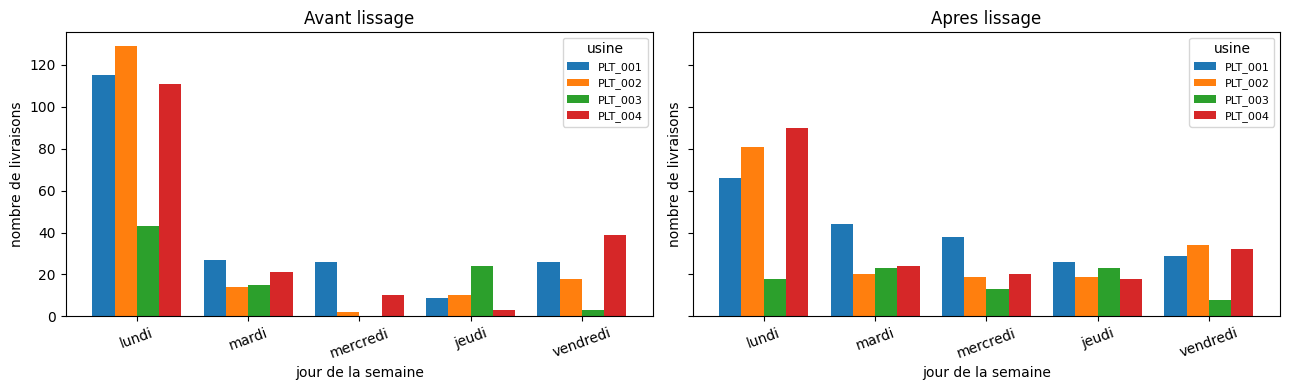

In [13]:
def lissage(candidats, meilleur, tolerance):
    """Choisit par usine un profil dans la tolerance qui equilibre la charge journaliere (R4)."""
    choix = {}
    cout = 0.0
    for usine in sorted({pl for (s, pl) in candidats}):
        couples_usine = [c for c in candidats if c[1] == usine and candidats[c]]
        couples_usine.sort(key=lambda c: -meilleur[c]["cout"])     # du plus cher au moins cher
        charge = defaultdict(int)
        for c in couples_usine:
            seuil = meilleur[c]["cout"] * (1 + tolerance) + 1e-9
            toleres = [r for r in candidats[c] if r["cout"] <= seuil]
            def equilibre(r):
                essai = dict(charge)
                for d in r["jours"]:
                    essai[d] = essai.get(d, 0) + 1
                vec = np.array([essai.get(np.datetime64(d, "D"), 0) for d in jours_ouvres])
                return (vec.max(), float(vec.std()), r["cout"], r["livraisons"])
            choisi = min(toleres, key=equilibre)
            choix[c] = choisi
            cout += choisi["cout"]
            for d in choisi["jours"]:
                charge[d] += 1
    return choix, cout

choix_final, cout_final = lissage(CANDIDATS, meilleur, TOLERANCE_LISSAGE)
ajout = cout_final - cout_etape1
print("APRES LISSAGE (tolerance", f"{TOLERANCE_LISSAGE:.0%}", ")")
print("  cout      :", round(cout_final, 2), "EUR")
print("  ajout vs etape 1 :", round(ajout, 2), "EUR (", round(ajout / cout_etape1 * 100, 3), "% )")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
tracer_charge(charge_par_jour_semaine(meilleur), "Avant lissage", a1)
tracer_charge(charge_par_jour_semaine(choix_final), "Apres lissage", a2)
plt.tight_layout()
plt.show()

**Notre constat :** le lissage n'ajoute que **76 €** (**+0,09 %**), un coût
quasi nul. En échange, la charge est bien plus régulière : le pire jour d'une usine
passe de **33 à 22 livraisons**. Nous respectons R4 sans sacrifier l'économie.

## Section 7 : Les solutions comparées, et notre choix

Nous comparons cinq solutions sur le périmètre : la situation actuelle, le
regroupement simple du milestone 2, et trois versions de notre moteur.

,solution,cout,camions,livraisons,charge max jour/usine,gain EUR,gain %
0,A. situation actuelle (baseline),143422.43,1604,1599,47,0.00,0.0
1,B. regroupement lundi (milestone 2),87924.69,719,706,53,55497.74,38.7
2,"C. meilleur profil, profils du PDF",86718.86,698,685,41,56703.57,39.5
3,"D. meilleur profil, profils elargis",82710.91,657,645,33,60711.52,42.3
4,E. D + lissage 2 % (RETENUE),82786.80,657,645,22,60635.63,42.3


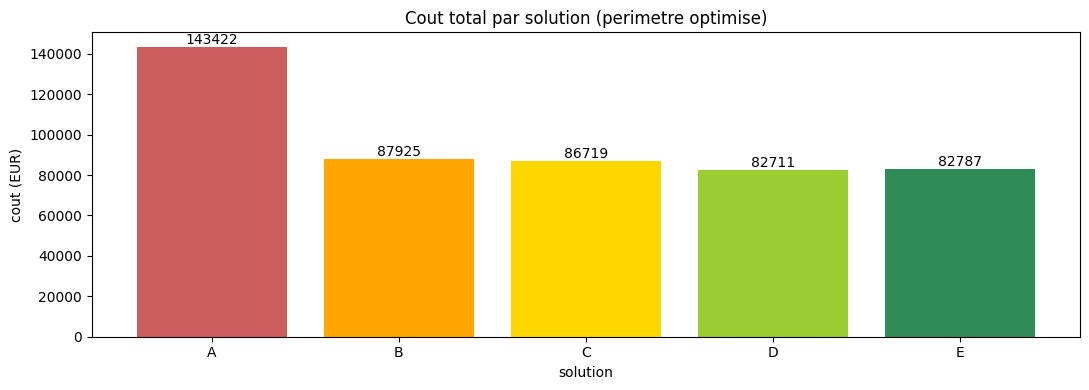

In [14]:
def charge_max_jour_usine(choix):
    """Plus grosse charge d'un jour dans une usine (une date, une usine)."""
    c = defaultdict(int)
    for (s, pl), b in choix.items():
        for d in b["jours"]:
            c[(pl, pd.Timestamp(d))] += 1
    return max(c.values()) if c else 0

# B : regroupement simple le lundi (milestone 2).
cout_B = 0.0
camions_B = 0
charge_B = defaultdict(int)
for (s, pl), g in opt.groupby(["supplier_id", "plant"]):
    for sem, gg in g.groupby("semaine"):
        camions = charger_camions(gg["weight"].values, gg["volume"].values)
        cout_B += cout_camions(camions, gg["ligne_grille"].iloc[0])
        camions_B += len(camions)
        charge_B[(pl, pd.Timestamp(sem))] += 1

# A : charge de la situation actuelle.
charge_A = defaultdict(int)
for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"]):
    charge_A[(pl, dt)] += 1

# C : meilleur profil, profils du PDF seulement.
cand_pdf = evaluer_tous(idx_pdf)
meilleur_pdf = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_pdf.items()}
cout_C = sum(b["cout"] for b in meilleur_pdf.values())

def camions_liv(choix):
    """Total (camions, livraisons) d'une solution."""
    return sum(b["camions"] for b in choix.values()), sum(b["livraisons"] for b in choix.values())

camC = camions_liv(meilleur_pdf)
camD = camions_liv(meilleur)
camE = camions_liv(choix_final)
comparaison = pd.DataFrame([
    {"solution": "A. situation actuelle (baseline)", "cout": round(BASELINE, 2), "camions": camions_actuel,
     "livraisons": opt.groupby(["supplier_id", "plant", "date"]).ngroups,
     "charge max jour/usine": max(charge_A.values())},
    {"solution": "B. regroupement lundi (milestone 2)", "cout": round(cout_B, 2), "camions": camions_B,
     "livraisons": sum(charge_B.values()), "charge max jour/usine": max(charge_B.values())},
    {"solution": "C. meilleur profil, profils du PDF", "cout": round(cout_C, 2), "camions": camC[0],
     "livraisons": camC[1], "charge max jour/usine": charge_max_jour_usine(meilleur_pdf)},
    {"solution": "D. meilleur profil, profils elargis", "cout": round(cout_etape1, 2), "camions": camD[0],
     "livraisons": camD[1], "charge max jour/usine": charge_max_jour_usine(meilleur)},
    {"solution": "E. D + lissage 2 % (RETENUE)", "cout": round(cout_final, 2), "camions": camE[0],
     "livraisons": camE[1], "charge max jour/usine": charge_max_jour_usine(choix_final)},
])
comparaison["gain EUR"] = (BASELINE - comparaison["cout"]).round(2)
comparaison["gain %"] = ((BASELINE - comparaison["cout"]) / BASELINE * 100).round(1)
display(comparaison)

fig, ax = plt.subplots(figsize=(11, 4))
barres = ax.bar(["A", "B", "C", "D", "E"], comparaison["cout"],
                color=["indianred", "orange", "gold", "yellowgreen", "seagreen"])
ax.set_title("Cout total par solution (perimetre optimise)")
ax.set_xlabel("solution"); ax.set_ylabel("cout (EUR)")
for b, v in zip(barres, comparaison["cout"]):
    ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom")
plt.tight_layout()
plt.show()

**Notre choix : la solution E.** Elle **respecte toutes les règles**. Elle
garde presque toute l'économie de D (**42,3 %**, à 76 € près). Et elle **équilibre
la semaine** (pire jour divisé par rapport à D). Les profils élargis (D) battent les
profils du PDF seuls (C : 86 719 € contre 82 711 €), ce qui justifie H18.

**Étude de sensibilité.** Nous regardons l'effet de nos deux réglages : la
tolérance de lissage (H17) et, pour information seulement, l'avance maximale (notre
règle R1 reste 7 jours).

In [15]:
sens_tol = []
for tol in (0.0, 0.02, 0.05):
    ch, co_ = lissage(CANDIDATS, meilleur, tol)
    sens_tol.append({"TOLERANCE_LISSAGE": f"{tol:.0%}", "cout": round(co_, 2),
                     "charge max jour/usine": charge_max_jour_usine(ch)})
display(pd.DataFrame(sens_tol))

sens_av = []
for am in (7, 14):
    cand_am = evaluer_tous(idx_tous, avance_max=am)
    best_am = {cle: min(v, key=lambda r: r["cout"]) for cle, v in cand_am.items() if v}
    sens_av.append({"AVANCE_MAX": f"{am} jours", "cout etape 1": round(sum(b["cout"] for b in best_am.values()), 2)})
print("Pour information seulement (notre regle R1 reste 7 jours) :")
display(pd.DataFrame(sens_av))

,TOLERANCE_LISSAGE,cout,charge max jour/usine
0,0%,82710.91,22
1,2%,82786.80,22
2,5%,83101.35,20


Pour information seulement (notre regle R1 reste 7 jours) :


,AVANCE_MAX,cout etape 1
0,7 jours,82710.91
1,14 jours,60436.47


**Notre constat :** augmenter la tolérance de 0 % à 5 % ne change presque rien
au coût (de 82 711 € à 83 101 €) tout en équilibrant un peu plus : **2 %** est un
bon compromis. Passer l'avance à 14 jours ferait tomber le coût à **60 436 €**, mais
cela violerait notre règle R1 ; nous ne le retenons pas, nous le notons seulement.

## Section 8 : Nos fonctions de validation

Avant d'annoncer un résultat, nous le **vérifions**. Nous reconstruisons d'abord le
contenu détaillé des camions de notre solution E, puis nous passons tous les
contrôles. Si l'un échoue, nous nous arrêtons.

In [16]:
# Contenu detaille des camions de la solution retenue (E).
SOLUTION = {cle: evaluer_profil(COUPLES[cle], ch["idx"], detail=True) for cle, ch in choix_final.items()}

lignes_camions = []
numero = 0
for (s, pl), r in SOLUTION.items():
    for date_liv, camions in r["contenu"]:
        for (poids, volume, parts) in camions:
            numero += 1
            cid = f"C{numero:05d}"
            for meta, part_p, part_v, frac in parts:
                lignes_camions.append({"camion_id": cid, "supplier_id": s, "plant": pl,
                    "date_livraison": date_liv.date(), "material": meta["material"],
                    "unloading_point": meta["unloading_point"], "date_besoin": meta["date_besoin"].date(),
                    "avance_jours": (meta["date_besoin"] - date_liv).days,
                    "quantite": round(meta["quantite"] * frac, 3), "poids": round(part_p, 3),
                    "volume": round(part_v, 4)})
contenu_camions = pd.DataFrame(lignes_camions)
print("Camions de la solution E :", numero, "| lignes chargees :", len(contenu_camions))

Camions de la solution E : 657 | lignes chargees : 4264


In [17]:
def valider(solution, contenu, cout_annonce):
    """Passe tous les controles de la solution ; affiche OK / ECHEC et s'arrete si un echoue."""
    controles = []
    # 1. chaque ligne livree une fois : poids et volumes conserves.
    c1 = abs(opt["weight"].sum() - contenu["poids"].sum()) < 1 and abs(opt["volume"].sum() - contenu["volume"].sum()) < 0.1
    controles.append(("lignes conservees (poids et volume)", c1))
    # 2. avance entre 0 et 7 jours, jamais de retard.
    av = contenu["avance_jours"]
    controles.append(("avance entre 0 et 7 jours", bool((av >= 0).all() and (av <= AVANCE_MAX).all())))
    # 3. jours ouvres, pas de semaine fermee, pas avant l'horizon.
    dl = pd.to_datetime(contenu["date_livraison"])
    c3 = bool((dl.dt.weekday < 5).all() and (~dl.map(semaine_fermee)).all() and (dl >= d0).all())
    controles.append(("lundi-vendredi, hors semaine fermee, dans l'horizon", c3))
    # 4. capacite des camions.
    cap = contenu.groupby("camion_id").agg(p=("poids", "sum"), v=("volume", "sum"))
    controles.append(("capacite 24 500 kg / 110,4 m3", bool((cap["p"] <= CAP_POIDS + 1e-3).all() and (cap["v"] <= CAP_VOLUME + 1e-3).all())))
    # 5. un camion = un seul couple.
    c5 = bool((contenu.groupby("camion_id")[["supplier_id", "plant"]].nunique() <= 1).all().all())
    controles.append(("un seul couple par camion", c5))
    # 6. chaque couple ne livre que les jours de son profil.
    c6 = True
    for cle, r in solution.items():
        jours_profil = PROFILS[r["idx"]]["jours"]
        for date_liv, camions in r["contenu"]:
            if pd.Timestamp(date_liv).weekday() not in jours_profil:
                c6 = False
    controles.append(("chaque couple suit son profil", c6))
    # 7. cout recalcule a partir des camions == cout annonce.
    recalc = 0.0
    for cid, g in contenu.groupby("camion_id"):
        recalc += prix_camion(COUPLES[(g["supplier_id"].iloc[0], g["plant"].iloc[0])]["ligne"], g["poids"].sum())
    controles.append(("cout coherent avec les camions", abs(recalc - cout_annonce) < 1))
    for nom, okc in controles:
        print(f"  [{'OK' if okc else 'ECHEC'}] {nom}")
    if not all(okc for _, okc in controles):
        raise AssertionError("Une validation a echoue : nous ne publions pas ce resultat.")
    print("Toutes les validations passent.")
    return True

valider(SOLUTION, contenu_camions, cout_final)

  [OK] lignes conservees (poids et volume)
  [OK] avance entre 0 et 7 jours
  [OK] lundi-vendredi, hors semaine fermee, dans l'horizon
  [OK] capacite 24 500 kg / 110,4 m3
  [OK] un seul couple par camion
  [OK] chaque couple suit son profil
  [OK] cout coherent avec les camions
Toutes les validations passent.


True

**Notre constat :** les **sept contrôles passent**. Chaque ligne est livrée une
fois, jamais en retard ni plus de 7 jours en avance, uniquement en semaine, sans
dépasser la capacité, un seul couple par camion, chaque couple sur son profil, et le
coût recalculé colle au coût annoncé. Notre résultat est fiable.

## Section 9 : Nos résultats

Cout       : avant 143422.43 -> apres 82786.8 EUR  ( 60635.63 EUR, 42.3 % )
Camions    : avant 1604 -> apres 657
Livraisons : avant 1599 -> apres 645
Objectif du milestone 2 (au moins 35 %) : ATTEINT


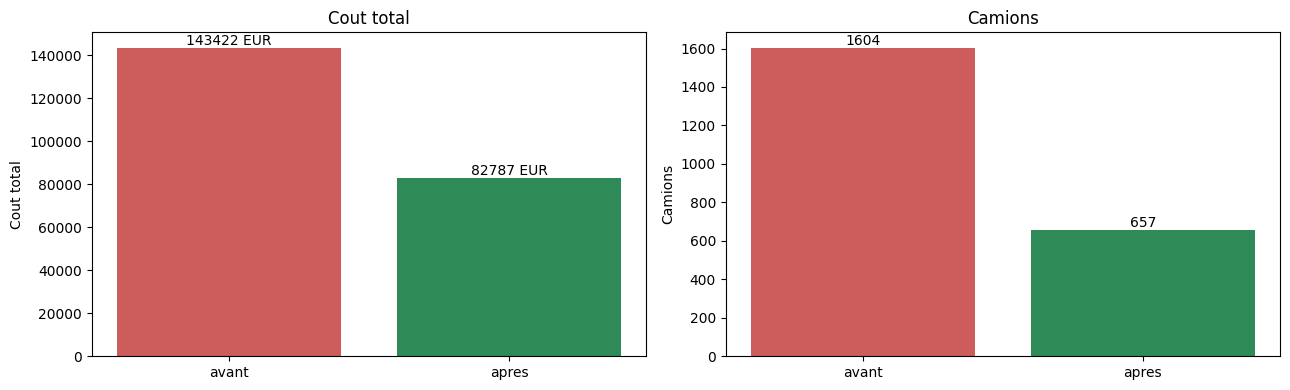

In [18]:
gain = BASELINE - cout_final
livraisons_avant = opt.groupby(["supplier_id", "plant", "date"]).ngroups
livraisons_apres = sum(b["livraisons"] for b in choix_final.values())
print("Cout       : avant", round(BASELINE, 2), "-> apres", round(cout_final, 2),
      "EUR  (", round(gain, 2), "EUR,", round(gain / BASELINE * 100, 1), "% )")
print("Camions    : avant", camions_actuel, "-> apres", camE[0])
print("Livraisons : avant", livraisons_avant, "-> apres", livraisons_apres)
print("Objectif du milestone 2 (au moins 35 %) :", "ATTEINT" if gain / BASELINE * 100 >= 35 else "non atteint")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4))
for ax, vals, titre, unite in [(a1, [BASELINE, cout_final], "Cout total", " EUR"),
                               (a2, [camions_actuel, camE[0]], "Camions", "")]:
    barres = ax.bar(["avant", "apres"], vals, color=["indianred", "seagreen"])
    ax.set_title(titre); ax.set_ylabel(titre)
    for b, v in zip(barres, vals):
        ax.text(b.get_x() + b.get_width() / 2, v, str(round(v)) + unite, ha="center", va="bottom")
plt.tight_layout()
plt.show()

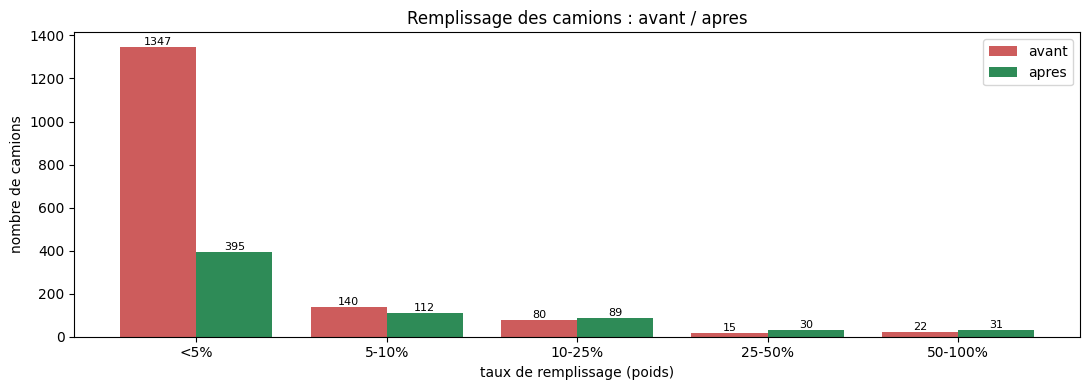

Remplissage median : avant 1.33 % -> apres 2.89 %


In [19]:
# Remplissage des camions, avant et apres.
def remplissages(choix_contenu):
    """Taux de remplissage (poids) de chaque camion d'une solution."""
    return [poids / CAP_POIDS * 100 for r in choix_contenu.values() for _, cams in r["contenu"] for (poids, v, p) in cams]

remp_avant = [poids / CAP_POIDS * 100 for (s, pl, dt), g in opt.groupby(["supplier_id", "plant", "date"])
              for (poids, v, p) in charger_camions(g["weight"].values, g["volume"].values)]
remp_apres = remplissages(SOLUTION)

bornes = [0, 5, 10, 25, 50, 100.0001]
libelles = ["<5%", "5-10%", "10-25%", "25-50%", "50-100%"]
ca = pd.cut(remp_avant, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
cb = pd.cut(remp_apres, bins=bornes, labels=libelles, include_lowest=True).value_counts().reindex(libelles)
x = np.arange(len(libelles))
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(x - 0.2, ca.values, width=0.4, label="avant", color="indianred")
ax.bar(x + 0.2, cb.values, width=0.4, label="apres", color="seagreen")
ax.set_title("Remplissage des camions : avant / apres")
ax.set_xlabel("taux de remplissage (poids)"); ax.set_ylabel("nombre de camions")
ax.set_xticks(x); ax.set_xticklabels(libelles); ax.legend()
for i, v in enumerate(ca.values): ax.text(i - 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
for i, v in enumerate(cb.values): ax.text(i + 0.2, v, str(int(v)), ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.show()
print("Remplissage median : avant", round(np.median(remp_avant), 2), "% -> apres", round(np.median(remp_apres), 2), "%")

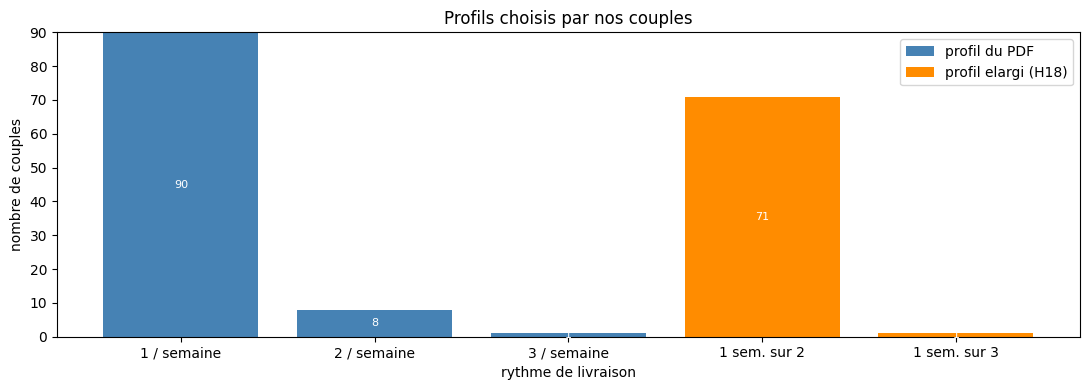

Couples avec un profil elargi (H18) : 72 sur 171


In [20]:
# Profils choisis, par rythme, en distinguant PDF et profils elargis.
def rythme(p):
    """Rythme lisible d'un profil pour le graphique."""
    if p["periode"] == 1:
        return f"{len(p['jours'])} / semaine"
    return f"1 sem. sur {p['periode']}"

compte = defaultdict(lambda: [0, 0])   # rythme -> [PDF, elargi]
for b in choix_final.values():
    p = PROFILS[b["idx"]]
    compte[rythme(p)][0 if p["type"] == "PDF" else 1] += 1
ordre = sorted(compte, key=lambda r: (len(r), r))
pdfv = [compte[r][0] for r in ordre]
elav = [compte[r][1] for r in ordre]
fig, ax = plt.subplots(figsize=(11, 4))
ax.bar(ordre, pdfv, label="profil du PDF", color="steelblue")
ax.bar(ordre, elav, bottom=pdfv, label="profil elargi (H18)", color="darkorange")
ax.set_title("Profils choisis par nos couples")
ax.set_xlabel("rythme de livraison"); ax.set_ylabel("nombre de couples")
for i, (a, b2) in enumerate(zip(pdfv, elav)):
    if a: ax.text(i, a / 2, str(a), ha="center", va="center", color="white", fontsize=8)
    if b2: ax.text(i, a + b2 / 2, str(b2), ha="center", va="center", color="white", fontsize=8)
ax.legend()
plt.tight_layout()
plt.show()
print("Couples avec un profil elargi (H18) :", sum(elav), "sur", len(choix_final))

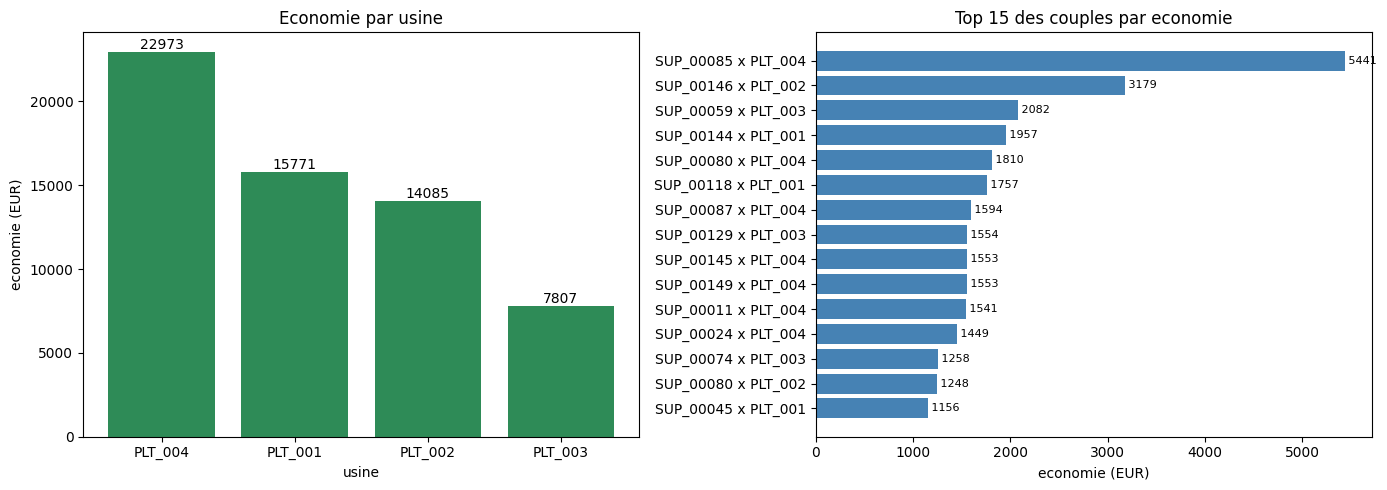

In [21]:
# Economie par usine et top 15 des couples.
eco = pd.DataFrame([{"supplier_id": s, "plant": pl,
                     "eco": (sum(cout_camions(charger_camions(g["weight"].values, g["volume"].values), COUPLES[(s, pl)]["ligne"])
                                 for _, g in COUPLES[(s, pl)]["df"].groupby("date"))) - choix_final[(s, pl)]["cout"]}
                    for (s, pl) in COUPLES])
eco_usine = eco.groupby("plant")["eco"].sum().sort_values(ascending=False)
top15 = eco.sort_values("eco", ascending=False).head(15)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))
barres = a1.bar(eco_usine.index, eco_usine.values, color="seagreen")
a1.set_title("Economie par usine"); a1.set_xlabel("usine"); a1.set_ylabel("economie (EUR)")
for b, v in zip(barres, eco_usine.values): a1.text(b.get_x() + b.get_width() / 2, v, str(round(v)), ha="center", va="bottom")
etiq = top15["supplier_id"] + " x " + top15["plant"]
a2.barh(etiq, top15["eco"], color="steelblue"); a2.invert_yaxis()
a2.set_title("Top 15 des couples par economie"); a2.set_xlabel("economie (EUR)")
for i, v in enumerate(top15["eco"]): a2.text(v, i, " " + str(round(v)), va="center", fontsize=8)
plt.tight_layout()
plt.show()

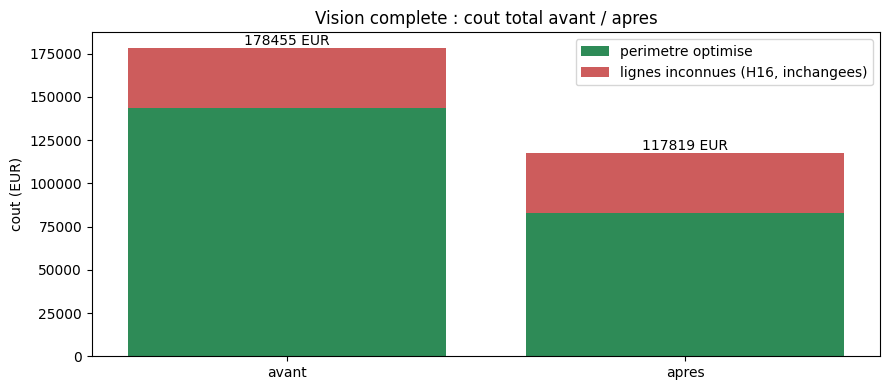

Cout total (avec inconnues) : avant 178454.85 -> apres 117819.22 EUR


In [22]:
# Vision complete : en ajoutant les lignes inconnues (identiques avant et apres).
COUT_INCONNUES = 35032.42   # H16, calcule au milestone 2
avant_total = BASELINE + COUT_INCONNUES
apres_total = cout_final + COUT_INCONNUES
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(["avant", "apres"], [BASELINE, cout_final], color="seagreen", label="perimetre optimise")
ax.bar(["avant", "apres"], [COUT_INCONNUES, COUT_INCONNUES], bottom=[BASELINE, cout_final],
       color="indianred", label="lignes inconnues (H16, inchangees)")
ax.set_title("Vision complete : cout total avant / apres"); ax.set_ylabel("cout (EUR)")
for i, tot in enumerate([avant_total, apres_total]):
    ax.text(i, tot, str(round(tot)) + " EUR", ha="center", va="bottom")
ax.legend()
plt.tight_layout()
plt.show()
print("Cout total (avec inconnues) : avant", round(avant_total, 2), "-> apres", round(apres_total, 2), "EUR")

**Notre constat :** sur le périmètre, nous passons de **143 422 €** à
**82 787 €**, soit **60 636 € (42,3 %) d'économie** : l'objectif des 35 % est
**atteint**. Nous divisons les camions (1 604 -> 657) et les livraisons
(1 599 -> 645). Le remplissage médian d'un camion passe de **1,3 % à 2,9 %**, et les
camions sous 5 % fondent de **1 347 à 395**. L'usine **PLT_004** concentre la plus
grosse économie (**22 973 €**) ; le couple le plus rentable, SUP_00085 x PLT_004,
économise **5 441 €** à lui seul. Vision complète, lignes inconnues comprises, nous
passons de **178 455 €** à **117 819 €**.

## Section 10 : Nos sorties

Notre moteur produit deux sorties demandées par le TD, plus un résumé des économies.

In [23]:
# Sortie 1 : un profil par couple.
lignes1 = []
for (s, pl), r in SOLUTION.items():
    couple = COUPLES[(s, pl)]
    p = PROFILS[r["idx"]]
    cout_act = sum(cout_camions(charger_camions(g["weight"].values, g["volume"].values), couple["ligne"])
                   for _, g in couple["df"].groupby("date"))
    poids_cams = [poids for _, cams in r["contenu"] for (poids, v, pp) in cams]
    remp_moy = np.mean([w / CAP_POIDS * 100 for w in poids_cams]) if poids_cams else 0
    lignes1.append({"supplier_id": s, "plant": pl, "distance": couple["distance"],
        "envois_sem_actuels": round(couple["df"].groupby("date").ngroups / 6, 2),
        "profil": p["libelle"], "periode": p["periode"],
        "jours": ",".join(JOURS[j] for j in sorted(p["jours"])), "livraisons": r["livraisons"],
        "camions": r["camions"], "remplissage_moyen_%": round(remp_moy, 2),
        "cout_actuel": round(cout_act, 2), "cout_optimise": round(r["cout"], 2),
        "economie_eur": round(cout_act - r["cout"], 2),
        "economie_%": round((cout_act - r["cout"]) / cout_act * 100, 1) if cout_act > 0 else 0})
profils_couples = pd.DataFrame(lignes1)

# Les couples entierement inconnus : livraison actuelle conservee (H15).
couples_connus = set(COUPLES)
inconnus = sorted({(s, pl) for (s, pl) in planning[planning["statut"] != "optimise"].groupby(["supplier_id", "plant"]).groups} - couples_connus)
for s, pl in inconnus:
    profils_couples.loc[len(profils_couples)] = {"supplier_id": s, "plant": pl, "distance": np.nan,
        "envois_sem_actuels": np.nan, "profil": "livraison actuelle conservee (H15)", "periode": np.nan,
        "jours": "", "livraisons": np.nan, "camions": np.nan, "remplissage_moyen_%": np.nan,
        "cout_actuel": np.nan, "cout_optimise": np.nan, "economie_eur": 0.0, "economie_%": 0.0}
print("Sortie 1 :", len(profils_couples), "couples (dont", len(inconnus), "entierement inconnus). Extrait :")
display(profils_couples.head(6))

Sortie 1 : 180 couples (dont 9 entierement inconnus). Extrait :


,supplier_id,plant,distance,envois_sem_actuels,profil,periode,jours,livraisons,camions,remplissage_moyen_%,cout_actuel,cout_optimise,economie_eur,economie_%
0,SUP_00118,PLT_001,100.0,4.83,"1 semaine sur 2 (semaine 1) : lundi, vendredi",2.0,"lundi,vendredi",6.0,6.0,13.06,3210.51,1453.93,1756.58,54.7
1,SUP_00024,PLT_001,64.0,3.00,1 / semaine : lundi,1.0,lundi,6.0,6.0,26.42,2408.90,1403.25,1005.64,41.7
2,SUP_00045,PLT_001,95.0,3.83,1 / semaine : mardi,1.0,mardi,6.0,6.0,10.27,2482.47,1326.15,1156.32,46.6
3,SUP_00144,PLT_001,38.0,3.33,1 / semaine : lundi,1.0,lundi,6.0,6.0,47.22,3240.69,1283.49,1957.20,60.4
4,SUP_00136,PLT_001,59.0,2.50,1 / semaine : mercredi,1.0,mercredi,5.0,5.0,9.53,1516.61,950.06,566.55,37.4
5,SUP_00148,PLT_001,68.0,2.33,"1 semaine sur 2 (semaine 1) : lundi, vendredi",2.0,"lundi,vendredi",6.0,6.0,6.33,1347.67,936.32,411.34,30.5


In [24]:
# Sortie 2 : contenu de chaque camion (deja construit en section 8).
print("Sortie 2 :", len(contenu_camions), "lignes chargees dans", contenu_camions["camion_id"].nunique(), "camions. Extrait :")
display(contenu_camions.head(6))

# Resume des economies.
resume = pd.DataFrame([
    ("Cout avant (perimetre)", round(BASELINE, 2)),
    ("Cout apres (perimetre)", round(cout_final, 2)),
    ("Economie (EUR)", round(gain, 2)),
    ("Economie (%)", round(gain / BASELINE * 100, 1)),
    ("Camions avant", camions_actuel),
    ("Camions apres", camE[0]),
    ("Livraisons avant", livraisons_avant),
    ("Livraisons apres", livraisons_apres),
    ("Cout lignes inconnues (H16, inchange)", round(COUT_INCONNUES, 2)),
    ("Cout total avant (avec inconnues)", round(avant_total, 2)),
    ("Cout total apres (avec inconnues)", round(apres_total, 2)),
], columns=["indicateur", "valeur"])
display(resume)

Sortie 2 : 4264 lignes chargees dans 657 camions. Extrait :


,camion_id,supplier_id,plant,date_livraison,material,unloading_point,date_besoin,avance_jours,quantite,poids,volume
0,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000444,ULP_0045,2026-11-09,0,800.0,531.2,0.4200
1,C00001,SUP_00118,PLT_001,2026-11-09,MAT_001125,ULP_0045,2026-11-12,3,800.0,508.0,0.4200
2,C00001,SUP_00118,PLT_001,2026-11-09,MAT_001212,ULP_0012,2026-11-12,3,1640.0,483.1,0.5700
3,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-12,3,980.0,405.7,0.4307
4,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000881,ULP_0012,2026-11-12,3,500.0,230.0,0.4200
5,C00001,SUP_00118,PLT_001,2026-11-09,MAT_000598,ULP_0001,2026-11-10,1,490.0,202.9,0.4307


,indicateur,valeur
0,Cout avant (perimetre),143422.43
1,Cout apres (perimetre),82786.80
2,Economie (EUR),60635.63
3,Economie (%),42.30
4,Camions avant,1604.00
5,Camions apres,657.00
6,Livraisons avant,1599.00
7,Livraisons apres,645.00
8,"Cout lignes inconnues (H16, inchange)",35032.42
9,Cout total avant (avec inconnues),178454.85


In [25]:
# Enregistrement.
import os
DOSSIER = "../data/processed/"
os.makedirs(DOSSIER, exist_ok=True)
profils_couples.to_csv(DOSSIER + "profils_couples.csv", index=False)
contenu_camions.to_csv(DOSSIER + "contenu_camions.csv", index=False)
resume.to_csv(DOSSIER + "resume_economies.csv", index=False)
print("Fichiers enregistres dans", DOSSIER, ":")
print("  - profils_couples.csv   (", len(profils_couples), "couples )")
print("  - contenu_camions.csv   (", len(contenu_camions), "lignes )")
print("  - resume_economies.csv  (", len(resume), "indicateurs )")

Fichiers enregistres dans ../data/processed/ :
  - profils_couples.csv   ( 180 couples )
  - contenu_camions.csv   ( 4264 lignes )
  - resume_economies.csv  ( 11 indicateurs )


## Section 11 : Notre bilan

Notre moteur choisit, pour chaque couple fournisseur x usine, **un profil de
livraison stable**, regroupe les besoins dans des camions remplis au maximum, lisse
la charge dans la semaine, puis chiffre l'économie. Sur notre périmètre, il fait
tomber le coût de **143 422 € à 82 787 €**, soit **42,3 % d'économie** : l'objectif
des 35 % est dépassé. Nous pouvons nous y fier, car **sept validations** passent
(lignes conservées, avance respectée, capacité, un couple par camion, profil
respecté, coût cohérent) et notre moteur **refait exactement** la baseline du
milestone 2 (143 422,43 €). La recherche du meilleur profil couple par couple est
**exacte** grâce à R3, pas une approximation.

**Nos hypothèses de ce milestone :**

- **H17 (tolérance de lissage 2 %)** : pour équilibrer la semaine, nous acceptons au
  plus 2 % de coût en plus par couple. L'étude de sensibilité montre que l'effet sur
  le coût est minime ; à valider par l'équipe.
- **H18 (profils élargis, période 1 à 4 semaines)** : tester *une semaine sur deux*
  ou plus fait mieux que les seuls profils du PDF (82 711 € contre 86 719 €). La
  règle des 7 jours interdit d'elle-même les profils trop espacés.
- Rappel : **H13** (remplir un camion au maximum avant d'en ouvrir un autre),
  **H15** (nous n'optimisons que les lignes connues), **H16** (lignes inconnues au
  pire cas, 35 032 €, inchangées), **H7** (aucune livraison la semaine de Noël).

**Nos limites :**

- Les profils sont stables sur **6 semaines seulement** : sur un horizon plus long,
  il faudrait vérifier qu'ils tiennent.
- Le lissage est **glouton** : il équilibre bien la semaine, mais ce n'est pas
  forcément le meilleur équilibre possible.
- Les **lignes inconnues** ne sont pas optimisées ; compléter leurs données
  ouvrirait une économie supplémentaire.